## Task 1• Python di base sui dati forniti

**Consegna**: svolgere i primi calcoli con strutture dati, cicli e funzioni Python, senza metodi di analisi Pandas.

**Vincolo:** Pandas si usa solo per leggere i file e convertirli; somme, conteggi e classificazioni si calcolano con costrutti Python.

**Criterio di completamento:** len() di lista prodotti, dizionario regions e set delle categorie riportata; fascia assegnata a ogni prodotto; fatturato per categoria da fatturato_categoria(), da confrontare con il Task 3b

**Definizione richiesta:**  differenza tra lista, tupla, set e dizionario per mutabilita, ordine, duplicati e modalità di accesso (indice o chiave).

**La lista** tiene gli elementi nell’oridne in cui li inserisco, posso aggiungerli, toglierli o cambiarli quando voglio (mutabile), può avere elementi ripetuti e li prendo con la loro posizione, per esempio vendite[0] è la prima vendita. 

**La tupla** è oridnata come la lista e può avere ripetizioni, ma una volta creata non si può più cambiare, la uso per valori che devono restare fissi, come (“Italia”, ”Sud Europa”) e anche qua prendo gli elementi con la posizione. 

**Il set** non tiene un ordine e non accetta doppioni, se aggiungo un elemento che c’è già, lo ignora.

**Il dizionario** è fatto di coppie chiave- valore, le chiavi non si ripetono, posso modificarlo, mantiene l’ordine di insermento e prendo i valori con la chiave invece che con un numero. Per esempio “regions[7] mi dà la Svezia.

Task 1•

**Richiesta 1:** leggere products.csv e sales.json e convertirli con .to_dict (orient= "records") in liste di dizionari; costruire regions come dizionario (RegionID: (State, SalesRegion)} e il set delle categorie.

**Risposta:** 

Leggo i tre file e controllo dimension, colonne e valori mancanti prima di lavorarci. in Sales.json Quantity e SalesAmount hanno 100 valori mancanti su 2000.

lista prodotti contiene 12 prodotti, e 2000 transazioni di vendite.

le regioni sono 9 paesi raggruppati in 3 regioni{sud,centro e nord europa} le categorie sono 3 (Giocattoli, Outdoor, Giochi da tavolo)

In [1]:
#Task 1.1

import pandas as pd
# lettura senza salvare  
pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")
pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")

# lettura dei file: li salvo in variabili  
df_prodotti = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")
df_sales = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
df_regioni = pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")

#ispezione dimensioni, tipi e valori mancanti
print(df_prodotti.shape,df_sales.shape,df_regioni.shape)
df_prodotti.info()
df_sales.info()
df_regioni.info()
df_prodotti.head

(12, 4) (2000, 7) (9, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     object 
 2   Category     12 non-null     object 
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 516.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null   int64  
 1   ProductID    2000 non-null   int64  
 2   RegionID     2000 non-null   int64  
 3   ResellerID   2000 non-null   int64  
 4   SalesDate    2000 non-null   object 
 5   Quantity     1900 non-null   float64
 6   SalesAmount  1900 non-null   float64
dtypes: float64(2), int64(4), object(1)
memory usage: 109.5+ KB
<class

<bound method NDFrame.head of     ProductID       ProductName          Category  ListPrice
0           1       Bici Junior           Outdoor      129.0
1           2          Bici BMX           Outdoor      189.0
2           3       Monopattino           Outdoor       79.0
3           4    Pallone Calcio           Outdoor       19.9
4           5   Racchette Beach           Outdoor       14.5
5           6       Puzzle 1000  Giochi da tavolo       17.9
6           7    Gioco dell'Oca  Giochi da tavolo       12.5
7           8     Scacchi Legno  Giochi da tavolo       34.0
8           9   Costruzioni 500        Giocattoli       39.9
9          10  Bambola Classica        Giocattoli       24.9
10         11          Robot RC        Giocattoli       89.0
11         12     Macchinina RC        Giocattoli       59.0>

**Task 1.1**· 

Liste, dizionario regions e set delle categorie.

In [2]:
# Task 1.1

# da tabella a lista di dizionario: ogni riga diventa un dizionario
prodotti = df_prodotti.to_dict(orient ="records")
vendite = df_sales.to_dict(orient ="records")
print("Numero prodotti:",len(prodotti))
print("Numero vendite:",len(vendite))

# dizionario regions 
regions = {}
for r in df_regioni.to_dict(orient ="records"):
    regions[r["RegionID"]] = (r["State"], r["SalesRegion"])
print(regions)

# set delle categorie 
lista_categorie = []
for p in prodotti:
    lista_categorie.append(p["Category"])
category = set(lista_categorie)
print(category)


Numero prodotti: 12
Numero vendite: 2000
{1: ('Italia', 'Sud Europa'), 2: ('Francia', 'Sud Europa'), 3: ('Spagna', 'Sud Europa'), 4: ('Germania', 'Centro Europa'), 5: ('Austria', 'Centro Europa'), 6: ('Svizzera', 'Centro Europa'), 7: ('Svezia', 'Nord Europa'), 8: ('Norvegia', 'Nord Europa'), 9: ('Danimarca', 'Nord Europa')}
{'Outdoor', 'Giocattoli', 'Giochi da tavolo'}


Task 1•

**Richiesta 2:** con una list comprehension e un costrutto if/elif/else assegnare a ogni prodotto la fascia di prezzo: Bassa sotto 20 €,Media fino a 60 €, Alta oltre.

**Criterio di completamento:** fascia assegnata a ogni prodotto.

**Risposta:** a tutti i 12 prodotti è stata assegnata una fsacia di prezzo: 4 in fascia Alta (Bici Junior, Bici BMX, Monopattino,Robot RC), 4 Media (Scacchi Legno, Costruzioni 500, Bambola Classica,Macchinina RC), 4 Bassa (Pallone Calcio, Racchette Beach, Puzzle 1000, Gioco dell'Oca). le fascie sonon distrubuite in modo equlibrato tra tree fascie.

In [3]:
#Task 1.2

# funzione con if/elif/else : riceve un prezzo e restitusce la fascia
def fascia_prezzo (prezzo):
    if prezzo < 20 :
        return "Bassa"
    elif prezzo <= 60:
        return "Media"
    else:
        return "Alta"
print(fascia_prezzo(45))

fascia = [(p["ProductName"], fascia_prezzo(p["ListPrice"])) 
          for p in prodotti]
for f in fascia:
    print(f)


Media
('Bici Junior', 'Alta')
('Bici BMX', 'Alta')
('Monopattino', 'Alta')
('Pallone Calcio', 'Bassa')
('Racchette Beach', 'Bassa')
('Puzzle 1000', 'Bassa')
("Gioco dell'Oca", 'Bassa')
('Scacchi Legno', 'Media')
('Costruzioni 500', 'Media')
('Bambola Classica', 'Media')
('Robot RC', 'Alta')
('Macchinina RC', 'Media')


Task 1•

**Richiesta 3:** Scrivere la funzione fatturato_categoria(vendite, prodotti, categoria) che con un ciclo for somma SalesAmount della categoria, salta i valori mancanti e restituisce il totale con return.

**Criterio di completamento:** fatturato per categoria da fatturato_categoria(), da confrontare con il Task 3b.

**Risposta:** 

Il fatturato per categoria è :Outdoor 331998.4€, Giocattoli 174832.0€, Giochi da tavolo 53245.1€. 

Outdoor è la categoria che vende di più, Giochi da tavolo quella che vende di meno.

i 100 valori mancanti di SalesAmount sono stati saltati con math.isnan.

In [4]:
#Task 1.3

# dizionario di ricerca : ProductID e Category 
categoria_di = {}
for p in prodotti:
    categoria_di[p["ProductID"]] = p["Category"]
    
#print(categoria_di[1])

# fatturato per categoria: somma SalesAmount saltando i valori mancati
import math

def fatturato_categoria(vendite, prodotti, categoria):
    totale = 0 
    for v in vendite:
        if categoria_di[v["ProductID"]] == categoria:
            if not math.isnan(v["SalesAmount"]):
                totale = totale + v["SalesAmount"]
    return totale
print(fatturato_categoria(vendite, prodotti,"Outdoor"))

# fatturato per ogni categoria 
for c in category:
    print(c,round(fatturato_categoria(vendite, prodotti,c),2))


331998.3999999998
Outdoor 331998.4
Giocattoli 174832.0
Giochi da tavolo 53245.1


Task 1•

**Richiesta 4:** con un ciclo while contare le transazioni necessarie a superare 10.000 € di fatturato cumulato; mostrare le prime cinque transazioni con vendite{:5].

**Risposta:** servono 56 transazioni per superare 10.000€ di fatturato cumlato, totale raggiunto: 10164.8€. 
i valori mancanti di SalesAmount sono contati come transazioni ma valgono 0€. 
nelle prime cinque transazioni ci sono già 3 valori mancanti, quindi era necessario gestirli.

In [5]:
# Task 1.4

# lista degli importi : i valori mancanti diventano 0 
importi = []
for v in vendite:
    if math.isnan(v["SalesAmount"]):
        importi.append(0)
    else: 
        importi.append(v["SalesAmount"])
# ciclo while: somma una vendita alla volta finchè supero 10.000€
fatturato_cumulato = 0
n_transazioni = 0
while fatturato_cumulato <=10000:
    fatturato_cumulato = fatturato_cumulato + importi[n_transazioni]
    n_transazioni = n_transazioni +1
print("transazioni necessarie:", n_transazioni)
print("fatturato raggiunto:", round(fatturato_cumulato,2))

# le prime cinquie transazioni 
for v in vendite[:5]:
    print(v)
    

transazioni necessarie: 56
fatturato raggiunto: 10164.8
{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}
{'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}
{'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}
{'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}
{'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}


## Task 2• Lettura e ispezione dei dati

**Consegna:** leggere i quattro file in DataFrame e descriverne struttura e contenuto prima di qualsiasi modifica.

**Vincolo:** nessuna modifica al DataFrame in questo task: solo lettura. descrizione e selezione

**Criterio di completamento:** per ogni DataFrame sono riportati righe, colonne, tipi e conteggio dei non nulli.

**Definizione richiesta:** differenza tra Series e DataFrame e tra .loc[ ] (selezione per etichetta) e .iloc[ ] (selezione per posizione).

**Risposta:** 

**Series :** è una sola colonna di dati con il suo indice, cioè le etichette delle righe, 
per esmpio: df_sales["SalesAmount"] con una sola coppia di parentesi quadre, mi dà una Series.

**Un DataFrame** invece è una tabella con righe e colonne, dove ogni colonna è una Series.
Per esmpio: df_sales[["SalesAmount"]] con due coppie di parentesi, mi dà un DataFrame con una sola colonna, e df_products è un DataFrame con 4 colonne.

**Con .loc[]** seleziono per etichetta, cioè con i nomi delle righe e delle colonne oppure con una condizione, 
per esempio: df_products.loc[maschera] mi ha dato i 3 pordotti Outdoor sopra i 30€. Nello slicing con .loc[] la fine è inclusa. 

**Con .iloc[]** selezion per posizione cioè con i numeri delle righe e delle colonne contando da 0, per esempio: df_sales.iloc[10:20, 0:3] mi ha dato le righe da 10 a 19 e le prime 3 colonne, perchè con .iloc[] la fine è esculsa.

Task 2 •

**Richiesta 1:** Leggere i file con pd.read_csv(), p.read_excel() e pd.read_json() e riportare per ciascuno .shape, .info(), .head() e .tail().

**Risposta:** 

Prodotti contiene 12 righe e 4 colonne float(1), int(1), object(2), Senza valori nulli. 

Vendite contiene 2000 righe e 7 float(2), int(4), object(1): Quantity e SalesAmount hanno 100 valori mancanti ciascuna (1900 non nulli su 2000) ed entrambe sono di tipo float, SalesData è di tipo object, la data si leggi come testo. 

Regioni contiene 9 righe e 3 colonne int(1), object(2)), Senza valori nulli.

Rivenditori contiene 300 righe e 7 colonne float(1), int(6), Senza valori nuli.

In [6]:
# Task 2.1

# lettura ai quattro file in DataFrame e la descrizione della struttura di ciascuno 
import pandas as pd
pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")
pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")
pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-resellers.csv") 

# prodotti : struttura e contenuto(shape, info, head e tail).
df_products = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")
print(df_products.shape)
df_products.info()
print(df_products.head())
print(df_products.tail())

# vendite : struttura e contenuto(shape, info, head e tail).
df_sales = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
print(df_sales.shape)
df_sales.info()
print(df_sales.head())
print(df_sales.tail())

# regioni :struttura e contenuto(shape, info, head e tail).
df_regions =pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")
print(df_regions.shape)
df_regions.info()
print(df_regions.head())
print(df_regions.tail())

# rivenditori : struttura e contenuto(shape, info, head e tail).
df_resellers = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-resellers.csv") 
print(df_resellers.shape)
df_resellers.info()
print(df_resellers.head())
print(df_resellers.tail())

(12, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     object 
 2   Category     12 non-null     object 
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 516.0+ bytes
   ProductID      ProductName Category  ListPrice
0          1      Bici Junior  Outdoor      129.0
1          2         Bici BMX  Outdoor      189.0
2          3      Monopattino  Outdoor       79.0
3          4   Pallone Calcio  Outdoor       19.9
4          5  Racchette Beach  Outdoor       14.5
    ProductID       ProductName          Category  ListPrice
7           8     Scacchi Legno  Giochi da tavolo       34.0
8           9   Costruzioni 500        Giocattoli       39.9
9          10  Bambola Classica        Giocattoli       24.9
10         11          Robo

Task 2 •

**Richiesta 2:** con .describe() individuare minimo, massimo e media di Quantity e SalesAmount; convertire le due colonne in array NumPy e calcolare con un'operazione vettoriale il prezzo unitario di ogni vendita.

**Risposta:**

Con describe: Quantity ha minimo 1, massimo 14 e media 4,97 pezzi per vendita. 

SaleAmount ha minimo 12.50€, massimo 2.457.00€ e media 294.78€ 
I conteggi sono 1900 perché describe() ignora i valori mancanti 



In [7]:
# Task 2.2

# individuare minimo, massimo e media di Quantity e SalesAmount con .describe() 
print(df_sales[["Quantity","SalesAmount"]].describe())

# convertire le colonne Quantity e SalesAmount in arry Numpy
import numpy as np

arr_quantita = np.array(df_sales["Quantity"])
arr_importi= np.array(df_sales["SalesAmount"])

# calcolare il prezzo unitario di ogni vendita con un'operazione vettoriale 
prezzo_unitario = (arr_importi/arr_quantita)
print(prezzo_unitario)



          Quantity  SalesAmount
count  1900.000000  1900.000000
mean      4.966316   294.776579
std       2.206535   305.261212
min       1.000000    12.500000
25%       3.000000    89.000000
50%       5.000000   177.000000
75%       6.000000   387.000000
max      14.000000  2457.000000
[17.9  nan 59.  ... 19.9 19.9 39.9]


Task 2 • 

**Richiesta 3:** selezionare con .loc[ ] e una maschera booleana i prodotti di una categoria con ListPrice superiore a 30 €; con .iloc[ ] le righe da 10 a 19 e le prime tre colonne di sales.

**Criterio di completamento:** la selezione con .iloc[ ] restituisce 10 righe e 3 colonne.

**Risposta:** La selezione con.iloc[ ] restituisce 10 righe e 3 colonne, lo dimostra .shape(10,3)


In [8]:
# Task 2.3

# mashera booleana dei prodotti di categoria outdoor con list price superiore a 30€
maschera = (df_products["Category"] =="Outdoor") & (df_products["ListPrice"] > 30)
print(df_products.loc[maschera])


# con .iloc[] le righe da 10 a 19 e le prime tre colonne di sales
print(df_sales.iloc[10:20,0:3])
print(df_sales.iloc[10:20,0:3].shape)

   ProductID  ProductName Category  ListPrice
0          1  Bici Junior  Outdoor      129.0
1          2     Bici BMX  Outdoor      189.0
2          3  Monopattino  Outdoor       79.0
    SalesID  ProductID  RegionID
10      218          1         8
11     1136          1         9
12     1326          3         4
13     1063          9         7
14     1606         10         8
15     1283         12         1
16       98          3         4
17      156          6         8
18     1642         12         5
19     1644          4         7
(10, 3)


## Task 3a • Dati mancanti, filtri e ordinamento

**Consegna:** rendere il DataFrame delle vendite pronto per l'analisi, trattando i valori mancanti e isolando i sottoinsiemi
richiesti.

**Attenzione:** la mediana si calcola sui valori presenti prima del fillna(); dopo l'imputazione .isna().sum() di Quantity vale 0.

**Criterio di completamento:** tabella dei NaN prima e dopo il trattamento; numero di righe eliminate riportato in Markdown;
filtro e ordinamento verificati con .head (10).

**Definizione richiesta:** imputazione dei dati mancanti: cos'è, quando preferire media, mediana o eliminazione della riga e quale effetto ha ciascuna scelta sulla distribuzione.

**L’imputazione dei dati mancanti** vuol dire riempire un dato che manca con un valore stimato, così non devo buttare via tutta la riga. 

**Uso la Media** quando i dati sono abbastanza regolari, senza valori estremi (molto grandi o molto piccoli).

**Uso la Mediana** quando ci sono valori estermi, perchè la media si sposta verso di loro e la mediana no, per questo ho riempito Quantity con la mediana, cioè 5.

**Elimino la riga** quando i dati mancanti sono pochi oppure quando il dato è troppo importante per inventarlo, come SalesAmount ho tolto 100 righe su 2000.

**Ogni scelta** cambia un pò i dati, se riempio con la media o con la mediana, metto tanti valori uguali al centro e i dati sembrano meno vari di quanto sono, se elimino le righe non invento niente, ma ho meno dati, e se mancavano prorio dei dati casi particolari il risultato può cambiare.

Task 3a •
    
**Richiesta 1:** contare i NaN per colonna con .isna().sum() e calcolarne la percentuale sul numero totale di righe.


**Risposta**
i valori mancanti sono solo in Quantity e SalesAmount: 100 ciascuna, cioè il 5% delle 2000 righe. le altre colonne sono complete.

In [9]:
# Task 3a.1 

# rileggio le vendite orginale dal file, cosi il task 3 parte sempre da dati puliti
df_sales = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")

#conto i valori NaN per colonna (tabella prima)
nan_prima = df_sales.isna().sum()
print(nan_prima)

#percentuale di NAN sul numero totale di righe
percentuale_nan_prima = (nan_prima / len(df_sales) * 100).round(2)
print(percentuale_nan_prima)

SalesID          0
ProductID        0
RegionID         0
ResellerID       0
SalesDate        0
Quantity       100
SalesAmount    100
dtype: int64
SalesID        0.0
ProductID      0.0
RegionID       0.0
ResellerID     0.0
SalesDate      0.0
Quantity       5.0
SalesAmount    5.0
dtype: float64


Task 3a •

**Richiesta 2:** imputare Quantity con la mediana della colonna tramite fillna() ed eliminare con dropna() le righe con SalesAmount mancante, dichiarando il numero di righe rimosse.

**Risposta** ho riempito i 100 valori mancanti di Quantity con la mediana(5 pezzi), calcolato prima del fillna.
la scelta della mediana perchè non si fa influenzare dagli valori estremi. 
ho elementa con dropna() le righe con SalesAmount mancante. 
righe rimosse 100, restano 1900 righe. dopo il tratamento non ci sono più valori mancanti in nessuna colonna. 

In [10]:
# Task 3a.2

#calcolo la mediana di Quantity prima del fillna e la salvo in una variable 

mediana_qty= df_sales["Quantity"].median()
print(mediana_qty)

# riempio i NaN di Quantity con la medina e controllo che siano 0 
df_sales["Quantity"] = df_sales["Quantity"].fillna(mediana_qty)
print(df_sales["Quantity"].isna().sum())

#elimino con dropna() le righe con SalesAmount mancante e conto quante ne ho tolte
righe_prima = len(df_sales)
df_sales = df_sales.dropna(subset=["SalesAmount"])
righe_dopo = len(df_sales)
righe_rimosse = righe_prima - righe_dopo
print("Righe rimosse:",righe_rimosse)

#tabella dei Nan dopo il trattamento
nan_dopo = df_sales.isna().sum()
print(nan_dopo)
  

5.0
0
Righe rimosse: 100
SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
dtype: int64


Task 3a •

**Richiesta 3:** con .query() estrarre le transazioni con SalesAmount superiore al 90° percentile (quantile(0.9)) e ordinarle con sort_values() per data crescente e importo decrescente.

**Criterio di completamento:** tabella dei NaN prima e dopo il trattamento; numero di righe eliminate riportato in Markdown; filtro e ordinamento verificati con .head(10).

**Risposta**
il 90° percentile di SalesAmount è 756€ con .query() ho estratto le 162 vendite con importo superiore a 756€ e le ho ordinate con .sort_values() per data crescente e importo decrescente;

il.head(10) conferma il filtro e l'ordinamento. per esempio: il 5 marzo 2023 la vendita da 1032€ viene prima di quella da 945€. le vendite più grandi sono quasi tutte di Bici Junior e Bici BMX.

In [11]:
# Task 3a.3

#soglia del 90° precentile di SalesAmount
soglia_90 = df_sales["SalesAmount"].quantile(0.9)
print(soglia_90)

# con query() estraggo le vendite sopra la soglia
top_vendite = df_sales.query("SalesAmount > 756")

# ordino per data crescente e importo decrescente 
top_vendite = top_vendite.sort_values(["SalesDate","SalesAmount"], ascending= [True,False])
print(len(top_vendite))

#verifica del filtro o dell'ordinamento
print(top_vendite.head(10))

756.0
162
     SalesID  ProductID  RegionID  ResellerID   SalesDate  Quantity  \
32      1045          2         4          82  2023-01-16       6.0   
49      1872          2         7         204  2023-01-25       5.0   
52      1639          1         3         299  2023-01-27       9.0   
102      296          2         9         202  2023-02-25       5.0   
118     1462          2         2         224  2023-03-03       5.0   
121     1221          1         8         149  2023-03-05       8.0   
123     1753          2         8         151  2023-03-05       5.0   
168      283          2         2         100  2023-03-30      11.0   
217     1679          1         4          22  2023-04-27       5.0   
221      832          2         4          82  2023-04-28       6.0   

     SalesAmount  
32        1134.0  
49         945.0  
52        1161.0  
102        945.0  
118        945.0  
121       1032.0  
123        945.0  
168       2079.0  
217        774.0  
221       1134.0  

## Task 3b • Aggregazioni e combinazione dei DataFrame

**Consegna:** costruire una tabella unica dele vendite e calcolare il fatturato per le principali chiavi di analisi.

**Criterio di completamento:** righe dopo il merge uguali a quelle di sales; due tabelle aggregate; categoria con il fatturato più
alto indicata in Markdown.

**Definizione richiesta:** differenza tra merge() (unione su colonne chive), join() (unione sull'indice) e concat() (accodamento
di righe o colonne).

**Con merge()** unisco due tabelle mettendole una di fianco all'altra, usando una colonna chiave che hanno in comune. per esempio: ho unito le vendita con i prodotti usando ProductID, così ogni vendite ha preso nome, categoria  e prezzo del suo prodotto. con how="left" tengo tutte le righe della prima tabella, con how="inner" tengo solo quelle che trovano una corrispondenza.

**Con join()** faccio la stessa cosa, ma l'unione non avviene su una colonna, ma sull'indice delle righe, si usa quando la chiave è già stata messa come indice della tabella. 

**Con concat()** invece non uso nessuna chiave; accodo le tabelle, cioè le metto una sotto l'altra per aggiungere righe, oppure una accanto all'altra per aggiungere colonne, senza collegarle tra loro.

Task 3b •


**Richiesta 1:** unire sales con products e regions tramite merge() su ProductID e RegionID (how="left") e verificare che il numero di righe resti quello di sales.

**Criterio di completamento:** righe dopo il merge uguali a quelle di sales; due tabelle aggregate; categoria con il fatturato più alto indicata in Markdown.

**Risposta:** 
ho unito le vendite con i prodotti(chiave ProductID) e con le regioni (chiave RegionID) usando .merge()con how="left". 

le righe sono rimaste 1900 uguale a quelle di sales, senza valori NaN.

In [12]:
#Task 3b.1

# unisco vendite e prodotti sulla chiave ProductID
df_merge = df_sales.merge(df_products, on="ProductID", how ="left")

# unisco le regioni sulla chiave RegionID
df_merge = df_merge.merge(df_regions, on="RegionID", how ="left")

# verifico le righe restino quelle di Sales
print(len(df_sales),len(df_merge))

# controllo dei Nan
print(df_merge.isna().sum())
df_merge.info

1900 1900
SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
ProductName    0
Category       0
ListPrice      0
State          0
SalesRegion    0
dtype: int64


<bound method DataFrame.info of       SalesID  ProductID  RegionID  ResellerID   SalesDate  Quantity  \
0        1194          6         7         283  2023-01-01       4.0   
1        1747         12         3         281  2023-01-02       2.0   
2         947          7         8         166  2023-01-04       6.0   
3         577          3         4         285  2023-01-04       3.0   
4          78          3         8         107  2023-01-04       3.0   
...       ...        ...       ...         ...         ...       ...   
1895      326          3         1         280  2025-12-27       4.0   
1896      394          7         2         256  2025-12-29       5.0   
1897      196          4         8          50  2025-12-29       5.0   
1898      878          4         4          27  2025-12-30       8.0   
1899     1278          9         5          57  2025-12-30       9.0   

      SalesAmount      ProductName          Category  ListPrice     State  \
0            71.6      Puz

Task 3b • 

**Richiesta 2:** con groupby() e agg() calcolare fatturato totale, quantità totale e numero di transazioni per Category e per SalesRegion, ordinati per fatturato decrescente.

**Criterio di completamento:** righe dopo il merge uguali a quelle di sales; due tabelle aggregate; categoria con il fatturato più alto indicata in Markdown.

**Risposta:** 

la categoria con il fatturato più alto è Outdoor (331.998.40€, con 767 transazioni) seguita da Giocattoli (174.832.00€) e Giochi da tavolo (53.245.10€). i valori coincidono con quelli calcolati nel task 1.3 con fatturato_categoria().
Tra le regioni Centro Europa vende di più (201.062.20€) ma le tre regioni sono vicine tra loro. 

In [13]:
# Task 3b.2

# calcolo fatturato totale, quantità totale e numero di transazioni per Category
# con groupby() e agg() ordinato per fatturato decrescente
per_category = df_merge.groupby("Category").agg(
    fatturato = ("SalesAmount","sum"),
    quantita = ("Quantity","sum"),
    transazioni = ("SalesID","count")).sort_values("fatturato",ascending=False)
print(per_category)

# calcolo fatturato totale, quantità totale e numero di transazioni per SalesRegion
# con groupby() e agg() ordinato per fatturato decrescente
per_region = df_merge.groupby("SalesRegion").agg(
    fatturato = ("SalesAmount","sum"),
    quantita = ("Quantity","sum"),
    transazioni = ("SalesID","count")).sort_values("fatturato",ascending=False)
print(per_region)

                  fatturato  quantita  transazioni
Category                                          
Outdoor            331998.4    3800.0          767
Giocattoli         174832.0    3225.0          644
Giochi da tavolo    53245.1    2416.0          489
               fatturato  quantita  transazioni
SalesRegion                                    
Centro Europa   201062.2    3413.0          698
Nord Europa     190189.0    3175.0          633
Sud Europa      168824.3    2853.0          569


Task 3b •

**Richiesta 3:** separare le vendite 2025 dalle altre con un filtro e ricomporle con pd.concat(), verificando che la somma delle righe coincida con l'originale.

**Criterio di completamento:** righe dopo il merge uguali a quelle di sales; due tabelle aggregate; categoria con il fatturato più alto indicata in Markdown.

**Risposta:**
Con una maschera booleana su pd.datetime(SalesDate).dt.year ho separato le vendite 2025(640) da quelle degli altri anni(1260). 
le ho ricomposte con pd.concat() il risultato ha 1900 righe, come la tabella originale.

In [14]:
# Task 3b.3 

# filtro: separo le vendite 2025 dalle altre con un maschera booleana
maschera_2025 = pd.to_datetime(df_merge["SalesDate"]).dt.year == 2025

# separo i dati in due sottoinsiemi: vendite 2025 e vendite degli altri anni
vendite_2025 = df_merge[maschera_2025]
vendite_altre = df_merge[~maschera_2025]
print(len(vendite_2025),len(vendite_altre))

# recompongo i due sottoinsiemi con pd.concat()
df_concat = pd.concat([vendite_2025, vendite_altre])

# verifico che la somma delle righe coincida con l'orginale 
print(len(df_concat),len(df_merge))
print(len(df_concat) == (len(df_merge)))
                            

640 1260
1900 1900
True


## Task 3c • Serie temporali di vendita

**Consegna:** analizzare l'andamento delle vendite el tempo a partire dal campo SalesDate.

**Vincolo:** anno, mese e differenza in giorni si ricavano con .dt e operazioni tra date, non con operazioni sulle stringhe.

**Criterio di completamento:** SalesDate di tipo datetime64; serie mensile di 36 righe (gennaio 2023, dicembre 2025); mese
con il fatturato massimo e conteggio di Recent = True indicati in Markdown.

Task 3c •

**Richiesta 1:** convertire SalesDate con pd.to_datetime() e verificare il nuovo tipo con .dtypes.

**Criterio di completamento:**  SalesDate di tipo datetime64

**Risposta:** 
ho convertito SalesDate da testo(object) a data con pd.to_datetime();con dtypes il nuovo tipo è datetime64.

In [15]:
# Task 3c.1

# converto SalesDate da object a data con pd.to_datetime
df_merge["SalesDate"] = pd.to_datetime(df_merge["SalesDate"])

# verifico il nuovo tipo con dtypes
print(df_merge["SalesDate"].dtypes)

datetime64[ns]


Task 3c •

**Richiesta 2:** con 'accessor .dt estrarre anno, mese e giorno della settimana in tre nuove colonne.

**Criterio di completamento:** SalesDate di tipo datetime64; serie mensile di 36 righe (gennaio 2023, dicembre 2025); mese con il fatturato massimo e conteggio di Recente = True indicati in Markdown.

**Vincolo:** anno, mese e differenza in giorni si ricavano con .dt e operazioni tra date, non con operazioni sulle stringhe.

**Risposta:** con 'accessor .dt ho estratto da SalesDate tre nuove colonne: Anno(dt.year), Mese (dt.month) e Giorno della settimana (dt.day_name().
per esempio: la prima vendita del 1 gennaio 2023 è di Sunday.

In [16]:
# Task 3c.2

# estrago anno, mese e giorno della settimana con dt. in tre nuove colonne
df_merge["Anno"] = df_merge["SalesDate"].dt.year
df_merge["Mese"] = df_merge["SalesDate"].dt.month
df_merge["Giorno"] = df_merge["SalesDate"].dt.day_name()

#controllo le nuove colonne 
print(df_merge[["SalesDate","Anno","Mese","Giorno"]].head())
print(df_merge.columns)

   SalesDate  Anno  Mese     Giorno
0 2023-01-01  2023     1     Sunday
1 2023-01-02  2023     1     Monday
2 2023-01-04  2023     1  Wednesday
3 2023-01-04  2023     1  Wednesday
4 2023-01-04  2023     1  Wednesday
Index(['SalesID', 'ProductID', 'RegionID', 'ResellerID', 'SalesDate',
       'Quantity', 'SalesAmount', 'ProductName', 'Category', 'ListPrice',
       'State', 'SalesRegion', 'Anno', 'Mese', 'Giorno'],
      dtype='object')


Task 3c •

**Richiesta 3:** calcolare il fatturato mensile con groupby() su anno e mese e la variazione percentuale tra mesi consecutivi con pct_change().

**Criterio di completamento:** SalesDate di tipo datetime64; serie mensile di 36 righe (gennaio 2023, dicembre 2025); mese con il fatturato massimo e conteggio di Recente = True indicati in Markdown.

**Vincolo:** anno, mese e differenza in giorni si ricavano con .dt e operazioni tra date, non con operazioni sulle stringhe.

**Risposta:** raggruppando per Anno e Mese ho ottenuto la serie del fatturato mensile, di 36 righe (da gennaio 2023 a dicembre 2025). 

con pct.change() ho calcolato la variazione percentuale tra mesi consecutuivi; il primo mese è NaN perchè non ha un mese precedente. 

il mese con il fattturato massimo è maggio 2025 con 29.368.30€ +37,47% rispetto al mese precedente.

In [17]:
#Task 3c.3

# calcolo il fatturato mensile raggruppando per anno e mese
fatturato_mensile = df_merge.groupby(["Anno","Mese"]).agg(
    fatturato = ("SalesAmount","sum"))
print(fatturato_mensile)
print(len(fatturato_mensile))
print(fatturato_mensile.head())

# variazione percentuale tra mesi consecutivi con pct_change()
fatturato_mensile["variazione_%"] = (fatturato_mensile["fatturato"].pct_change() * 100).round(2)
print(fatturato_mensile.head())

# ordino i mesi oer fatturato decrescente e prendo il primo (il fatturato massimo)
print(fatturato_mensile.sort_values("fatturato", ascending=False).head(1))


           fatturato
Anno Mese           
2023 1       11499.8
     2        9414.9
     3       14917.2
     4       11077.9
     5       10806.7
     6       11637.3
     7       10161.0
     8       15387.5
     9       14361.2
     10      13340.5
     11      11597.0
     12      11604.4
2024 1       17359.8
     2        9701.8
     3       20455.7
     4       16703.8
     5       13579.1
     6       18679.5
     7       16802.9
     8       17218.8
     9       12921.5
     10      15710.2
     11      16276.4
     12      11765.5
2025 1       14385.1
     2       23337.1
     3       16348.2
     4       21363.6
     5       29368.3
     6       17765.2
     7       14791.0
     8       18042.4
     9       21273.2
     10      20215.7
     11      16428.7
     12      13776.6
36
           fatturato
Anno Mese           
2023 1       11499.8
     2        9414.9
     3       14917.2
     4       11077.9
     5       10806.7
           fatturato  variazione_%
Anno Mese        

Task 3c •

**Richiesta 4:** aggiungere la colonna booleana Recent: True se la vendita è avvenuta entro 180 giorni dall'ultima data presente nel dataset. False altrimenti.

**Criterio di completamento:**  SalesDate di tipo datetime64; serie mensile di 36 righe (gennaio 2023, dicembre 2025); mese con il fatturato massimo e conteggio di Recente = True indicati in Markdown.

**Risposta:** l'ultima data del dataset è il 30 dicembre 2025. 
ho calcolato i giorni passati tra ogni vendita e questa data con una sottrazione tra date e .dt.days. poi, ho creato la colonna booleana Recente(True se i giorni sono al massimo 180).
le vendite con Recente = True sono 315, cioè il 16,58% del totale.

In [18]:
#Task 3c.4

# ultima data del set
ultima_data = df_merge["SalesDate"].max()
print(ultima_data)

#giorni passati tra ogni vendita e l'ultima data
giorni_passati = (ultima_data - df_merge["SalesDate"]).dt.days

# colonna booleana Recente: True se la vendita è avvenuta entro 180 giorni
df_merge["Recente"] = giorni_passati <=180

#conta quante vendite sono recenti
print(df_merge["Recente"].sum())

# analisi extra:perecentuale delle vendite recenti sul totale
precentuale_recenti = round(df_merge["Recente"].sum()/ len(df_merge) * 100, 2)
print(precentuale_recenti)

2025-12-30 00:00:00
315
16.58


## Task 4 • Visualizzazione e storytelling

**Consegna:** produrre tre grafici obbligatori e uno opzionale, ciascuno in risposta a una domanda di business, scegliendo il tipo
di grafico in base al tipo di dato.

**Vincolo:** il titolo di ogni grafico enuncia il risultato (es. "I fatturato cresce del 12% nel 2025"), non l'argomento.

**Criterio di completamento:** grafico a linee, boxplot e heatmap (più le barre Plotly se svolte), ciascuno seguito da una cella
Markdown di due frasi: domanda di business e risposta letta dal grafico.


**Definizione richiesta:** criterio di scelta del grafico: andamento nel tempo (line), confronto tra categorie (barre), distribuzione
(boxplot), relazione tra variabili (heatmap o scatter).

**Il tipo di grafico** si sceglie in base al tipo di dato e alla domanda a cui voglio rispondere.

**Per mostrare un andamento nel tempo** uso un grafico a linee, perché collega i punti in ordine e fa vedere salite e discese. 
per esempio: il fatturato mese per mese dal 2023 al 2025.

**Per confrontare delle categorie** uso le barre, perché l'altezza di ogni barra si confronta subito con le altre.
per esempio: il fatturato per stato o per categoria.

**Per vedere la distribuzione di una variabile** uso il boxplot, che mostra la mediana, il 50% centrale dei valori e gli outlier. 
per esempio: l'importo delle vendite nelle tre categorie.

**Per vedere la relazione tra variabili** uso la heatmap delle correlazioni, quando voglio confrontare tante coppie di variabili insieme, oppure lo scatter, quando voglio guardare due variabili da vicino.

Task 4 • 

**1. Matplotlib:** grafico a line del fatturato mensile del Task 3c, con titolo, etichette degli assi con unità (€) e mese di picco evidenziato con un'annotazione.

Grafico a linee (Matplotlib) del fatturato mensile del Task 3c, con il mese di picco evidenziato da un punto rosso e un'annotazione.

   Anno  Mese  fatturato  variazione_%
0  2023     1    11499.8           NaN
1  2023     2     9414.9        -18.13
2  2023     3    14917.2         58.44
3  2023     4    11077.9        -25.74
4  2023     5    10806.7         -2.45
   Anno  Mese  fatturato  variazione_%       Data
0  2023     1    11499.8           NaN 2023-01-01
1  2023     2     9414.9        -18.13 2023-02-01
2  2023     3    14917.2         58.44 2023-03-01
3  2023     4    11077.9        -25.74 2023-04-01
4  2023     5    10806.7         -2.45 2023-05-01


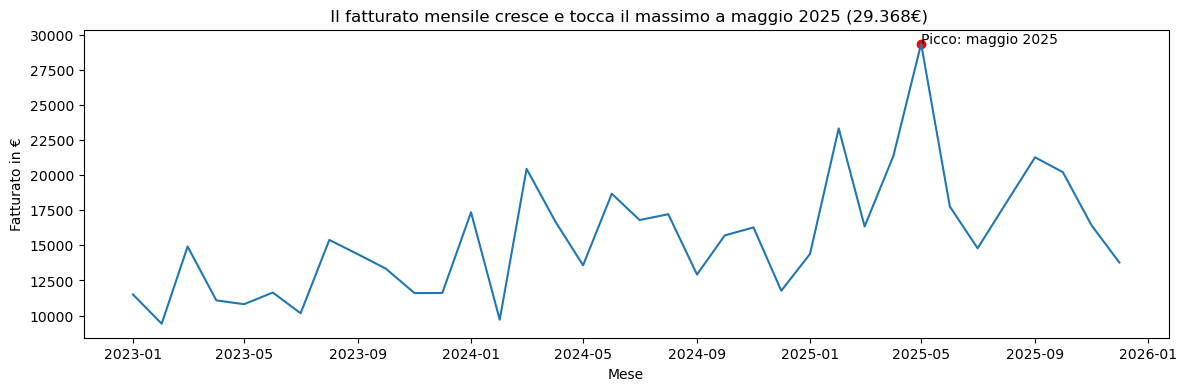

In [19]:
# Task 4.1

import matplotlib.pyplot as plt

# riporto Anno e Mese da indice a colonne
fm = fatturato_mensile.reset_index()
print(fm.head())

# preparo le tre infromazione della data
anni = fm["Anno"]
mesi = fm["Mese"]

# costriuisco la data: anno + mese + giorno
fm["Data"] = pd.to_datetime({"year": anni, "month": mesi, "day":1})
print(fm.head())

# grafico a linee del fatturato mensile
plt.figure(figsize=(14,4))
plt.plot(fm["Data"] ,fm["fatturato"])

# evidenzio il mese di picco: colore di accento e annotazione
plt.scatter(pd.Timestamp("2025-05-01"), 29368.3, color="red")
plt.annotate("Picco: maggio 2025", xy=(pd.Timestamp("2025-05-01"),29368.3))

plt.title(" Il fatturato mensile cresce e tocca il massimo a maggio 2025 (29.368€)")
plt.xlabel("Mese")
plt.ylabel("Fatturato in €")
plt.show()



**Domanda di business:**  come è cambiato il fatturato mensile di ToysGroup dal 2023 al 2025?

**Risposta:** il fatturato cresce nel tempo, con molti alti e bassi, da circa 10-15 milla € nel al mese nel 2023 fino al picco di maggio 2025 (29.368 €); dopo il picco cala verso fine 2025

Task 4 • 

**Consegna:**  produrre tre grafici obbligatori e uno opzionale, ciascuno in risposta a una domanda di business, scegliendo il tipo di grafico in base al tipo di dato.

**2. Seaborn:** boxplot di SalesAmount per categoria e heatmap della matrice di correlazione delle variabili numeriche di resellers.

Category
Giocattoli          236.0
Giochi da tavolo     89.5
Outdoor             316.0
Name: SalesAmount, dtype: float64


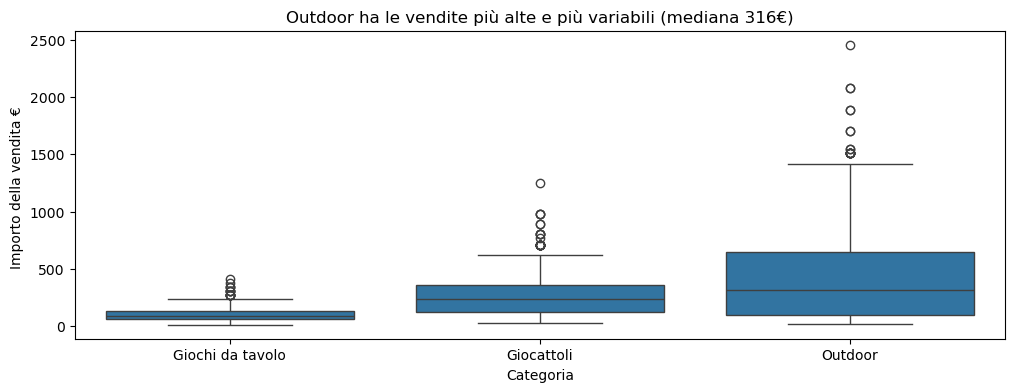

In [20]:
#Task 4.2

import seaborn as sns

print(df_merge.groupby("Category")["SalesAmount"].median())

# boxplot della distribuzione di SalesAmount per categoria 
plt.figure(figsize=(12,4))
sns.boxplot(data= df_merge, x= "Category", y= "SalesAmount")
plt.title("Outdoor ha le vendite più alte e più variabili (mediana 316€)")
plt.xlabel("Categoria")
plt.ylabel("Importo della vendita € ")
plt.show()

**Domanda di business:** gli importi delle vendite sono distribuiti allo stesso modo nelle tre categoria?

**Risposta:** No

Outdoor ha le vendite più alte e più variabili (mediana 316 €, con vendite fino a circa 2.457 €), mentre Giochi da tavolo ha vendite basse e molto simili tra loro (mediana 89,50 €); Giocattoli si trova nel mezzo (mediana 236 €)

**Task 4.2**  

Heatmap delle correlazioni dei rivenditori

   ResellerID  RegionID  Ordini12m  GiorniUltimoOrdine  ScontoMedio  Reclami  \
0           1         1         14                  65        0.131        1   
1           2         7          9                 149        0.117        1   
2           3         6         21                   1        0.065        2   
3           4         4         18                 162        0.011        1   
4           5         4         22                  98        0.120        0   

   Churn  
0      0  
1      0  
2      0  
3      1  
4      0  
                    Ordini12m  GiorniUltimoOrdine  ScontoMedio  Reclami  Churn
Ordini12m                1.00               -0.78         0.06     0.07  -0.35
GiorniUltimoOrdine      -0.78                1.00        -0.02    -0.10   0.43
ScontoMedio              0.06               -0.02         1.00    -0.01  -0.01
Reclami                  0.07               -0.10        -0.01     1.00   0.07
Churn                   -0.35                0.43        -

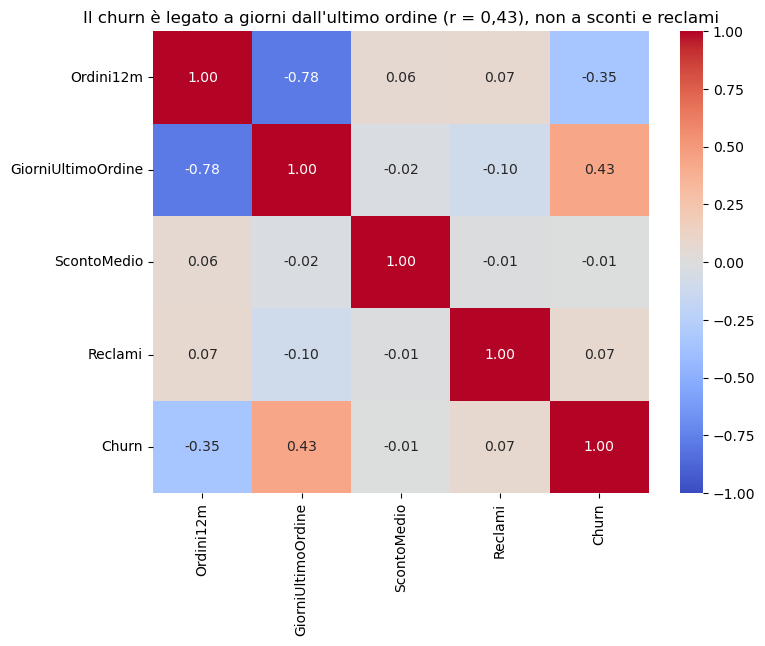

In [21]:
#Task 4.2

# guardo la tabella dei rivenditori prima di scegliere le colonne
print(df_resellers.head())

# colonne numeriche dei rivenditori (escludo gli ID che sono solo etichette)
cols = ["Ordini12m","GiorniUltimoOrdine","ScontoMedio","Reclami","Churn"]

# matrice di correlazione
corr = df_resellers[cols].corr()
print(corr.round(2))

# heatmap 
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Il churn è legato a giorni dall'ultimo ordine (r = 0,43), non a sconti e reclami")
plt.show()

**Domanda da business:** cosa fa capire che un rivenditori sta per andarsene (churn)?

**Risposta:** i rivenditori che non ordinano da tanti giorni o che hanno fatto pochi ordini nell'anno se ne vanno più spesso, invece lo sconto ricevuto e il numero di reclami non c'entrano con il churn. 

## Task 5 • Correlazione e regressione lineare

**Consegna:** stimare il fatturato mensile con un modello lineare e usarlo per una previsione dei mesi successivi.

**Criterio di completamento:** tabella comparativa dei due modelli (coefficienti, R² train, R² test); tre valori previsti in € se svolta la previsione: coefficiente dell'indice del mese interpretato come variazione in € per mese.

**Definizione richiesta:** R²: cos'è, intervallo dei valori, cosa misura e perché una correlazione o un R² alto non dimostrano un
rapporto di causa ed effetto.

**L'R²**(R quadro) è un numero che indica quanto un modello riesce a spiegare il risultato che vuole prevedere. 
Per esempio: l'R² mostra quanto il mio modello spiega le differenze di fatturato da un mese all'altro.
Di solito l'R² varia da 0 a 1, Con un valore di 1 il modello spiega tutto e le previsioni sono perfette.
Con un valore di 0 il modello non spiega nulla, è come prevedere sempre la media. 
Nella fase di test, l'R² può essere anche negativo se il modello sbaglia più della media, come è accaduto nei miei due modelli.
Per esempio: un valore di R² pari a 0,477 vuol dire che il modello spiega circa metà del movimento del fatturato. L'altra metà dipende da fattori che il modello non conosce.
Una correlazione alta o un R² alto non dimostrano che una cosa causi l'altra. Indicano solo che due cose si muovono insieme nei dati. Per esempio, d'estate si vendono più gelati e si registrano più scottature; però i gelati non causano le scottature, ma il caldo fa aumentare sia i gelati sia le scottature.

Task 5 • 

**1.** con .corr() calcolare la correlazione tra fatturato mensile, quantità mensile e numero di rivenditori attivi nel mese, indicando la coppia più correlata.

**Risposta:** la coppia più correlata e fatturato e quantità mensile (r = 0,87 , correlazione forte e postiva)
nei mesi in cui si vendono più pezzi, il fatturato è più alto. 
il numero di rivenditori attivi è collegato in modo moderato sia al fatturato (r = 0,56) sia alla quantità(0,67).

In [22]:
#Task 5.1

# tabella mensile: fatturato e quantita e numero di rivenditori attivi diveri per ogni mese
mensile = df_merge.groupby(["Anno","Mese"]).agg(
    fatturato = ("SalesAmount","sum"),
    quantita = ("Quantity","sum"),
    rivenditori = ("ResellerID","nunique")
).reset_index()
print(mensile.head())

# assegno a ogni mese un numero progressivo, da 1 (gennaio 2023)a 36 (dicembre 2025)
mensile["indice_mese"] = np.arange(1,37)
print(mensile.head())
print(mensile.tail())

# matrice di correlazione tra fatturato, quantità e rivenditori attivi
corr_mensile = mensile[["fatturato","quantita","rivenditori"]].corr()
print(corr_mensile.round(2))



   Anno  Mese  fatturato  quantita  rivenditori
0  2023     1    11499.8     214.0           51
1  2023     2     9414.9     171.0           43
2  2023     3    14917.2     223.0           48
3  2023     4    11077.9     220.0           51
4  2023     5    10806.7     188.0           49
   Anno  Mese  fatturato  quantita  rivenditori  indice_mese
0  2023     1    11499.8     214.0           51            1
1  2023     2     9414.9     171.0           43            2
2  2023     3    14917.2     223.0           48            3
3  2023     4    11077.9     220.0           51            4
4  2023     5    10806.7     188.0           49            5
    Anno  Mese  fatturato  quantita  rivenditori  indice_mese
31  2025     8    18042.4     348.0           52           32
32  2025     9    21273.2     385.0           62           33
33  2025    10    20215.7     327.0           48           34
34  2025    11    16428.7     282.0           43           35
35  2025    12    13776.6     294.0 

Task 5 • 

**2.** dopo train_test_split(test_size=0.2, random_state=42), stimare con LinearRegression una regressione semplice (fatturato su indice del mese) e una multipla (indice del mese, quantita, rivenditori attivi).

Regressione semplice stimo il fatturato mensile in funzione dell'indice del mese (1 = gennaio 2023, 36 = dicembre 2025) 
con LinearRegression, dopo train_test_split(test_size=0.2,random_state=42).

In [23]:
# Task 5.2

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. Regressione semplice : fatturato in funzione dell'indice del mese 
X = mensile[["indice_mese"]]
y = mensile["fatturato"]
print("X:",X.shape, "Y:",y.shape)

# 2. split train/test : 20% nel test, random_state=42 per risultati ripetibili
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Train:",len(X_train),"Test:",len(X_test))

# 3. creo il modello e lo addestro solo sul train 
model_semplice = LinearRegression()
model_semplice.fit(X_train,y_train)
print("Intercetta:",model_semplice.intercept_)
print("Coefficiente:",model_semplice.coef_[0])

#4. R² del modello semplice su train e test 
r2_train_s = model_semplice.score(X_train,y_train)
r2_test_s = model_semplice.score(X_test,y_test)
print("R²train:",round(r2_train_s,3))
print("R²test:",round(r2_test_s ,3))

#verifico quali mesi sono finiti nel test
print(X_test.index)
print(mensile.loc[X_test.index])

X: (36, 1) Y: (36,)
Train: 28 Test: 8
Intercetta: 10602.52906483967
Coefficiente: 303.5771860432264
R²train: 0.477
R²test: -1.879
Index([35, 13, 26, 30, 16, 31, 21, 12], dtype='int64')
    Anno  Mese  fatturato  quantita  rivenditori  indice_mese
35  2025    12    13776.6     294.0           47           36
13  2024     2     9701.8     192.0           38           14
26  2025     3    16348.2     305.0           49           27
30  2025     7    14791.0     273.0           45           31
16  2024     5    13579.1     276.0           48           17
31  2025     8    18042.4     348.0           52           32
21  2024    10    15710.2     281.0           50           22
12  2024     1    17359.8     309.0           58           13


**Risposta:** 
il coefficiente dell'indice del mese è circa 303,58. secondo il modello, ogni mese il fatturato cresce di circa 303,58€ (circa 3.643 € in un anno). 
sul train l'R² è 0,477 , quindi il modello spiega circa metà dell'andamento del fatturato. 
sul test l'R² è -1,879: è negativo, cioè sui mesi dei test il modello sbaglia più che se usassi semplicemente la media. 
questo succede perchè nel test ci sono solo 8 mesi, presi a caso, e i mesi del 2025 finiti nel test (tra 13776.6 € 18042.4 €) non sono i mesi più alti di quell'anno, mentre la retta prevede sempre una crescità. 

### Task 5.2 · Regressione multipla
Stimo il fatturato mensile in funzione di indice del mese, quantità e rivenditori attivi, con lo stesso split (test_size=0.2, random_state=42).

**Task 5.2** · Regressione multipla
Stimo il fatturato mensile in funzione di indice del mese, quantità e rivenditori attivi, con lo stesso split (test_size=0.2, random_state=42).

In [24]:
#Task 5.2

# 1. Modello multipli : fatturato in funzione di indice del mese, quantità e rivenditori 
X_multi = mensile[["indice_mese","quantita","rivenditori"]]
y_multi = mensile["fatturato"]

# 2. split con gli stessi parametri del modello semplice 
Xm_train,Xm_test,ym_train,ym_test = train_test_split(X_multi,y_multi,test_size=0.2,random_state=42)

# 3. addestro il modello solo sul train
model_multi = LinearRegression()
model_multi.fit(Xm_train,ym_train)
print("Intercetta:",model_multi.intercept_)
print(dict(zip(X_multi.columns,model_multi.coef_)))

# 4. R² su train e test 
r2_train_m = model_multi.score(Xm_train,ym_train)
r2_test_m = model_multi.score(Xm_test,ym_test)
print("R²train:",round(r2_train_m,3))
print("R²test:", round(r2_test_m,3))

Intercetta: 6323.672621231093
{'indice_mese': np.float64(-78.10534205233141), 'quantita': np.float64(85.305435116757), 'rivenditori': np.float64(-229.35501330598368)}
R²train: 0.836
R²test: -0.415


**Risposta** con tre variabili (indice del mese, quantità e rivenditori) l'R² sul train sale a 0,836 quindi il modello spiegia meglio i mesi su cui ha imparato. sul test l'R² migliora ma resta negativo (-0,415). 
la grande differneza tra train e test può essere un sengale di overfitting, ma con solo 8 mesi di test non si può dire con certezza. 
alcuni coefficienti sono negativi (indice del mese e rievenditori) perchè le variabili sono legate tra loro e il modello non riesce a separare l'effetto di ogniuna; non vuol dire che più rivenditori fanno predere soldi. 

**Task 5.3** · Tabella comparativa dei due modelli
Metto a confronto il modello semplice e il modello multiplo: intercetta, coefficienti, R² su train e R² su test.

In [25]:
# Task 5.2 

#tabella comparativa dei due modelli 
confronto = pd.DataFrame({
    "modello":["semplice","multiplo"],
    "intercetta":[model_semplice.intercept_,model_multi.intercept_],
    "coef_indice_mese":[model_semplice.coef_[0],model_multi.coef_[0]],
    "coef_quantita":[None,model_multi.coef_[1]],
    "coef_rivenditori":[None,model_multi.coef_[2]],
    "R2_train":[r2_train_s,r2_train_m],
    "R2_test":[r2_test_s,r2_test_m]
})
print(confronto.round(3))



    modello  intercetta  coef_indice_mese  coef_quantita  coef_rivenditori  \
0  semplice   10602.529           303.577            NaN               NaN   
1  multiplo    6323.673           -78.105         85.305          -229.355   

   R2_train  R2_test  
0     0.477   -1.879  
1     0.836   -0.415  


**Commento** 
il modello multiplo spiega molto meglio i mesi di train (R²  0.836 contro 0.477) e anche sul test va meglio del semplice (-0.415  contro -1.879) ma tutti e due R² negativo sul test, quindi sui mesi nuovi sbagliano più della semplice media. 
il modello semplice è più facile da leggere, ogni mese il fatturato previsto cresce di circa 303,58€. nel modello multiplo invece i coefficienti sono difficili da interpretare, perche le variabili sono legate tra loro. con solo 36 mesi di dati, e 8 nel test, nessuno dei due modelli è affidabile per fare previsioni. 

Task 5 • 

**3.** riportare coef_, intercept_ e R² su train e test per i due modelli; (opzionale) prevedere con il modello semplice il fatturato dei tre mesi successivi all'ultimo disponibile.

**Risposta:** con il modello semplice, il fatturato previsto è 21.834,89€ a gennaio 2026, 22.138,46€ a febbraio 2026 e 22.442,04€ a marzo 2026(ogni mese + 303,58€ il coefficiente). qeuste previsioni sono da prendere con cautela, la retta prevede sempre una crescita, ma a fine 2025 il fatturato stava calando(dicembre 2025:13.777€)e il modello ha un R² negativo sul test.


In [26]:
# Task 5.3

# previsione dei 3 mesi successivi all'ultimo disponibile (gennaio, febbraio, marzo 2026) 
mesi_futuri = pd.DataFrame({"indice_mese":[37,38,39]})
previsioni = model_semplice.predict(mesi_futuri)
print(previsioni.round(2))



[21834.88 22138.46 22442.04]


## Task 6a• Classificazione del churn dei rivenditori

**Consegna:** prevedere quali rivenditori smetteranno di ordinare con una regressione logistica e valutare gli errori del modello

**Criterio di completamento:** tabella delle metriche per le due soglie; soglia motivata in Markdown; diagnosi train/test con i due
valori: AUC con roc auc score() (opzionale).

**Definizione richiesta:** apprendimento supervisionato e non supervisionato: dati richiesti, obiettivo e un esempio per ciascuno
tratto dallo scenario.

**Nell’apprendimento supervisionato**, i dati hanno già la risposta giusta. Oltre alle caratteristiche (X), c’è una colonna che indica il risultato vero, chiamata target (y). Il modello impara osservando questi esempi, dove sappiamo già cosa deve dare come risultato. L’obiettivo è imparare a prevedere la risposta per nuovi casi.
Per esempio: nel Task 6a ho usato la colonna Churn (0 = resta, 1 = se ne va) per insegnare alla regressione logistica a capire quali rivenditori smetteranno di ordinare.

**Nell’apprendimento non supervisionato**, le cose sono diverse. I dati non hanno una risposta giusta. Non c’è nessuna colonna target. Non si tratta di prevedere qualcosa, ma di scoprire da soli delle strutture nei dati. L’obiettivo è trovare gruppi di casi simili tra loro.
Per esempio: con l’algoritmo K-Means si possono raggruppare i rivenditori in base a ordini, giorni dall’ultimo ordine, sconto e reclami. Senza dire al modello a priori quali gruppi esistono. Il modello cerca da solo delle analogie e le raggruppa.


Task 6a • 


**1.** separare X (Ordini12m, GiorniUltimoOrdine, ScontoMedio, Reclami) e y (Churn); applicare train test _split con stratify=y e
StandardScaler con fit solo sul training set.

Separo X(le 4 caratteristiche dei rivenditori) e y (Churn), divido i dati con train_test_split(test_size=0.20,stratif=y, random_state=42) e preparo il modello con StandardScaler e LogisticRegression in una pipeline, addestrata solo sul train. 

**Risposta:** il train ha 240 rivenditori e il test 60. grazie a stratify la quota di churn è quasi uguale nei grouppi (23,8% nel train e 23,3% nel test) come nei dati completi (71 su 300). le variabili hanno numeri di granadezza molto diverse (per esempio i giorni sono decine o centinaia, lo sconto è in decimale), quindi le ho messo sulla stessa scala con StandardScaler, addestrato solo sui train per non uasre informazine del test.

In [27]:
# Task 6a.1

#X: le 4 caratteristiche dei rivenditori y:il churn(0= resta, 1= se ne va)
X_churn = df_resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y_churn = df_resellers["Churn"]

# split con stratify per mantenere la stessa quota di churn in train e test 
Xc_train,Xc_test,yc_train,yc_test = train_test_split(
    X_churn,y_churn,test_size=0.20, stratify=y_churn,random_state=42)
print("Xc_train:",Xc_train.shape, "Xc_test:",Xc_test.shape)
print("Quota churn train:",round(yc_train.mean(),3))
print("Quota churn test:",round(yc_test.mean(),3))

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# pipline : standard Scaler + regressione logistica 
# il fit avviene solo sul train : lo scaler impara media e deviazione standard solo dal train

modello_churn = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
modello_churn.fit(Xc_train,yc_train)
print("Modello addestrato.")

Xc_train: (240, 4) Xc_test: (60, 4)
Quota churn train: 0.238
Quota churn test: 0.233
Modello addestrato.


Task 6a • 

**2.** addestrare LogisticRegression, ottenere predict() e predict_proba() e costruire la matrice di confusione con soglia 0,5 e
con soglia 0,3.

Con il modello addestrato ottengo per ogni rivenditore del test la decisione finale(predict,soglia 0,5) e la probabilità di churn (predict_proba), poi costruisco la matrice di confusione con soglia 0,5 e con soglia 0,3. 

**Risposta:** predict() dà la decisione finale (0=resta, 1=se ne va), mentre predict_proba() dà la probabilità di churn.
con soglia 0,5 il modello trova solo 4 rivenditori che se ne vanno su 14 e ne perde 10 (falsi negativi), con 4 falsi allarmi. 
con soglia 0,3 ne trova 10 su 14 e ne perde solo 4, ma i flasi allarmi salgono a 10. 
per esempio: un rivenditori con probabiltià 0,486 se n'è andato davvero, con soglia 0,5 non viene segnalato, con 0,3 sì. 

   reale  prob_churn  pred_05
0      0    0.166138        0
1      0    0.045961        0
2      1    0.148202        0
3      1    0.485817        0
4      1    0.625036        1
5      0    0.051805        0
6      0    0.648996        1
7      0    0.067111        0
8      0    0.237002        0
9      0    0.036860        0


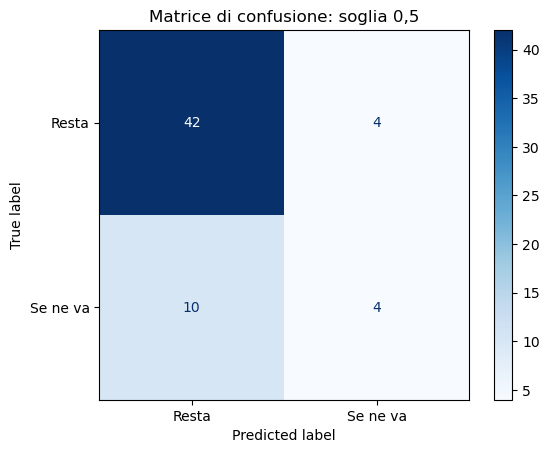

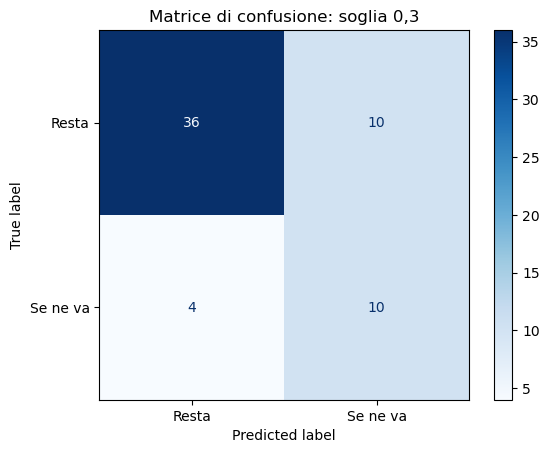

In [28]:
#Task 6a.2

# la decisione finale con soglia 0,5: 0=resta , 1=se ne va 
pred_05 = modello_churn.predict(Xc_test)

#la probabilità di churn di ogni rivenditore(sceonda colonna di predict_proba)
prob_churn = modello_churn.predict_proba(Xc_test)[:,1]

#tabella di confronto: realta, probabiltà e decisone 
confronto_churn = pd.DataFrame({
    "reale": yc_test.to_numpy(),
    "prob_churn":prob_churn,
    "pred_05": pred_05,
})
print(confronto_churn.head(10))

# matrice di confusione con soglia 0,5
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(yc_test,pred_05,display_labels=["Resta","Se ne va"],cmap="Blues")
plt.title("Matrice di confusione: soglia 0,5")
plt.show()

# matrice di confusione con soglia 0,3
pred_03=(prob_churn>=0.3).astype(int)
ConfusionMatrixDisplay.from_predictions(yc_test,pred_03,display_labels=["Resta","Se ne va"],cmap="Blues")
plt.title("Matrice di confusione: soglia 0,3")
plt.show()


Task 6a • 

**3.** calcolare Accuracy, Precision e Recall per le due soglie e confrontare l'Accuracy con la baseline Churn = 0.


Calcolo Accuracy, Precision e Recall per le due soglie (0,5 e 0,3) e le metto in una tabella, poi confronto l'Accuracy con la baseline, cioè un modello che dice sempre "resta"(churn=0), e calcolo l'AUC con roc_auc_score(). 

**Soglia scelta:**  scelgo la soglia 0,3 perchè il suo recall è più alto (0,714 contro 0,286): trovo 10 rivenditori che se ne vanno su 14, invece di 4. l'accuracy è la stessa con le due soglie(0,767), quindi conviene la soglia che perde meno rivenditori; un rivenditori perso senza accorgersene costa più di una faslo allarame. 

In [29]:
# Task 6a.3
from sklearn.metrics import accuracy_score,precision_score,recall_score,roc_auc_score

# metriche con soglia 0,5
acc_05 = accuracy_score(yc_test,pred_05)
prec_05 = precision_score(yc_test,pred_05)
rec_05 = recall_score(yc_test,pred_05)
print("Soglia 0,5 -> Accuracy:",round(acc_05,3),"Precision:",round(prec_05,3),"Recall:",round(rec_05,3))

# metriche con soglia 0,3
acc_03 = accuracy_score(yc_test,pred_03)
prec_03 = precision_score(yc_test,pred_03)
rec_03 = recall_score(yc_test,pred_03)
print("Soglia 0,3 -> Accuracy:",round(acc_03,3),"Precision:",round(prec_03,3),"Recall:",round(rec_03,3))

# tabella di delle metriche per le due soglie 
tabella_soglie = pd.DataFrame({
    "soglia":[0.5,0.3],
    "accuracy":[acc_05,acc_03],
    "precision":[prec_05,prec_03],
    "recall":[rec_05,rec_03]
})
print(tabella_soglie.round(3))

# quanti rivenditori del test restano davvero(churn=0)
quanti_restano = (yc_test ==0).sum()

# baseline : percentuale di chi resta = parte/totale
baseline = quanti_restano/len(yc_test)
print("Accuracy baseline:", round(baseline,3))

# AUC : calcolato con le probabiltà
auc= roc_auc_score(yc_test,prob_churn)
print("AUC:", round(auc,3))


Soglia 0,5 -> Accuracy: 0.767 Precision: 0.5 Recall: 0.286
Soglia 0,3 -> Accuracy: 0.767 Precision: 0.5 Recall: 0.714
   soglia  accuracy  precision  recall
0     0.5     0.767        0.5   0.286
1     0.3     0.767        0.5   0.714
Accuracy baseline: 0.767
AUC: 0.761


Task 6a •

**4.** confrontare Accuracy e Recall su train e test e classificare il modello come underfitting, buon adattamento o overfitting.

Confronto Accuracy e Recall sul train e sul test, con la solgia scelta (0,3), per capire se il modello è in underfitting, in buon adattamento o in overfitting.

**Risposta:** con soglia 0,3 l'accuracy è 0,742 sul train e 0,767 sul test, il recall è 0,754 sul train e 0,714 sul test. 
i valori sono vicini (diffrenze di 2-4 punti), quindi il modello è in buon adattamento, non ha imparato a memoria i dati di train e funziona in modo simile anche sui rivenditroi nuovi. le prestazoni sono discrete ma non ottime, l'accuracy è uguale alla baseline, quindi il valore del modello sta soprattutto nel recall.


In [30]:
# Task 6a.4

# probabilità e decisioni con soglia 0,3 anche sul Train
prob_train = modello_churn.predict_proba(Xc_train)[:,1]
pred_train_03 =(prob_train >=0.3).astype(int)

# accuracy e recall sul train e sul test (soglia 0,3)
print("Accuracy train:",round(accuracy_score(yc_train,pred_train_03),3))
print("Accuracy test:",round(acc_03,3))
print("Recall train:",round(recall_score(yc_train,pred_train_03),3))
print("Recall test:",round(rec_03,3))

Accuracy train: 0.742
Accuracy test: 0.767
Recall train: 0.754
Recall test: 0.714


## Task 6b • Segmentazione dei rivenditori con K-Means

**Consegna:** suddividere i rivenditori in segmenti omogenei per comportamento d'acquisto e confrontare i segmenti con il
churn.

**Criterio di completamento:** grafico del gomito con k motivato; tabella dei profili con nome e quota di churn per segmento;
segmento con il churn più alto indicato in Markdown.

**Definizione richiesta:** centroide e inerzia; motivo per cui K-Means non richiede una colonna y né la divisione train/test.

Il Centroide è il punto medio di un cluster, calcolato come media delle feature delle osservazioni che contiene.

L’inerzia è la somma delle distanze al quadrato tra l’osservazioni e il proprio centroide. 

L’obiettivo di K-Means è renderela la più bassa possibile, cioè rendere i cluster il più compatti possibile. Siccome l’inerzia diminuisce aumentando k, il numero di cluster lo sceglie l’analista prima dell’esecuzione, con il metodo del gomito. 

K- Means non richiede una colonna y perché è non supervisionato: i cluster non hanno un nome predefinito, e il significato di ogni gruppo si ricava dopo, dalle medie delle feature (come ho fatto con Attivi, Dormienti e Top clienti). Per lo stesso motivo non serve la divisione train/test: non c'è una risposta giusta da verificare, quindi si usano tutti i rivenditori disponibili.



Task • 6b 

**1**. calcolare il fatturato totale per rivenditore da sales con groupby(), standardizzare Ordini12m, GiorniUltimoOrdine e fatturato
e calcolare inertia_ per k da 1 a 10 con KMeans(n_init=10, random_state =42).

In [31]:
# Task 6b.1 

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# fatturato totale per rivenditore, dalle vendite pulite (df_merge)
fatt_riv = df_merge.groupby("ResellerID").agg(
    fatturato = ("SalesAmount","sum")
).reset_index()

# unisco il fatturato alla tabella dei rivenditorie (how = "left" : tengo tutti i 300 rivenditori)
df_km = df_resellers.merge(fatt_riv, on ="ResellerID",how = "left")

# alcuni rivenditori non hanno vendite il loro fatturato e NaN, quindi lo metto a 0
print("Rivenditori senza vendite:", df_km["fatturato"].isna().sum())
df_km["fatturato"] = df_km["fatturato"].fillna(0)

# standardizzo le 3 variabili: K-Means usa le distanze, quindi servono scale confrontabili 
colonne_km = ["Ordini12m","GiorniUltimoOrdine","fatturato"]
X_km = StandardScaler().fit_transform(df_km[colonne_km])

#inerzia per k da 1 a 10 
inerzia = []
for k in range(1,11):
    km_prova = KMeans(n_clusters=k, n_init=10, random_state=42)
    km_prova.fit(X_km)
    inerzia.append(km_prova.inertia_)
print([round(i, 1) for i in  inerzia])

Rivenditori senza vendite: 4
[900.0, 433.7, 319.2, 257.2, 225.6, 198.6, 180.7, 164.8, 149.7, 137.0]


Task • 6b

**2.** scegliere k con il metodo del gomito e assegnare i cluster con fit _predict() in una nuova colonna.

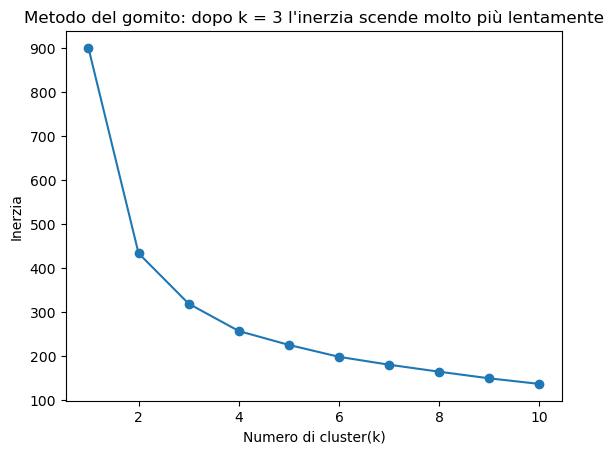

cluster
0     95
1    137
2     68
Name: count, dtype: int64


In [32]:
#Task 6b.2

# grafico del gomito: interzia per ogni k
plt.plot(range(1, 11), inerzia, marker="o")
plt.xlabel("Numero di cluster(k)")
plt.ylabel("Inerzia")
plt.title("Metodo del gomito: dopo k = 3 l'inerzia scende molto più lentamente")
plt.show()

# k scelto guardando il grafico : il punto dopo cui l'interzia scende molto più lentamente 
k_scelto = 3

# assegno a ogni rivenditore il suo cluster in una nuova colonna 
km = KMeans(n_clusters=k_scelto, n_init=10, random_state=42)
df_km["cluster"]= km.fit_predict(X_km)
print(df_km["cluster"].value_counts().sort_index())

**Risposta:** ho scelto k= 3. Nel grafico del gomito l'interzia scende passando da 1 a 2 e da 2 a 3 cluster, mentre dopo 3 la linea diventa quasi piatta, aggiungere altri cluster migliora poco. 
acnhe k = 2 era possibile, ma 3 gruppi descrivonon meglio i rivenditori e restano facili da usare per l'azienda.

Task • 6b

**3.** profilare i cluster con groupby() sulle variabili originali, assegnare un nome a ciascuno e calcolare la quota di churn per
cluster.


In [33]:
# Task 6b.3 

# profilo per ogni culster con le variabili orginali( non standardizzate)
# la media di churn (0/1) è la quoto di churn del cluster 

profili = df_km.groupby("cluster")[colonne_km +["Churn"]].mean()
print(profili.round(2))

# Task 6b.3 

# do un nome a ogni cluster guardando le medie, nell'ordine dei cluster(0,1,2)
profili["Nome"] = ["Attivi", "Dormienti","Top clienti"]
print(profili.round(2))

         Ordini12m  GiorniUltimoOrdine  fatturato  Churn
cluster                                                 
0            19.58               48.35    1514.70   0.11
1            12.42              141.48    1288.47   0.39
2            21.66               45.90    3524.38   0.10
         Ordini12m  GiorniUltimoOrdine  fatturato  Churn         Nome
cluster                                                              
0            19.58               48.35    1514.70   0.11       Attivi
1            12.42              141.48    1288.47   0.39    Dormienti
2            21.66               45.90    3524.38   0.10  Top clienti


**Risposta**: i tre segmenti sono Attivi: (19,58 ordini in media, utilmo ordine 48 giorni fa, 1.514,70€ di fatturato), Dormienti: (12,42 ordini, ultimo ordine 141 giorni fa, 1.288,47€) e Top clienti: ( 21,66 ordini, ultimo ordine 46 giorni fa, 3.524,38€). 
il segmento con il churn più alto è Dormienti: 39%, contro l'11% degil attivi e il 10% dei Top clienti. 
il modello ha trovato queste grouppo senza usare la colona Churn; per l'azienda sono i rivenditori da contattare per primi.

## Task 7 • Debugging, refactoring e versioning

Al for Coding - README e verifica finale inclusi

**Consegna:** ogni frammento contiene un errore o una pratica scorretta. Per ciascuno: individuare la causa con un assistente Al (ChatGPT, Claude o Anaconda Assistant), esquire la correzione nel notebook e riportare il prompt usato.

**Vincolo:** una correzione proposta dall'Al si accetta solo dopo averla eseguita nel notebook; per ogni caso vanno riportati
errore originale, causa e versione corretta.

**Versioning:** pubblicare notebook e file di dati su un repository GitHub, con un README che descrive scenario,task e istruzioni di esecuzione.

**Criterio di completamento:** quattro celle corrette ed eseguite senza errori; Caso 4 con nomi espliciti e docstring;repository GitHub con notebook, file di dati, README e almeno tre commit descrittivi.

**Task 7 · Caso 1: media del fatturato**

**Errore originale**

```
totale = 0
for v in sales["SalesAmount"]:
    totale += v
media = totale / len(sales)
```
**Causa:** SalesAmount ha 100 valori mancanti (NaN). Quando il ciclo somma un NaN non dà errore, ma il totale diventa NaN, e quindi anche la media è NaN. È un errore silenzioso: nessun messaggio di errore, solo un risultato sbagliato. Per questo i valori mancanti vanno saltati, oppure si usa .mean() di Pandas, che li ignora in automatico.

**Prompt usato:** "Ho questo codice Python che calcola la media di una colonna con un ciclo for. La colonna ha dei valori mancanti. Perché il risultato è sbagliato e come lo correggo con Pandas?"
la versione corretta, eseguita


In [ ]:
# Task 7 · Caso 1 - versione corretta

# .mean() di Pandas calcola la media ignorando in automatico i valori mancanti (NaN)
media = df_sales["SalesAmount"].mean()
print("Media del fatturato per vendita:", round(media, 2))

Media del fatturato per vendita: 294.78


**Task 7 · Caso 2: preparazione del modello**

**Errore originale:**

```
Caso 2: preparazione del modello
scaler = StandardScaler()
X_s = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = \
   train_test_split(X_s, y)
```
**Causa:** lo StandardScaler viene addestrato su tutti i dati prima dello split, quindi impara media e deviazione standard anche dal test. Il modello "sbircia" i dati della verifica e i risultati sul test sono troppo ottimisti. Lo split va fatto prima, e lo scaler va addestrato solo sul train (come nel Task 6a).

**Prompt usato:** "In questo codice applico StandardScaler prima di train_test_split. È corretto? Qual è il problema e qual è l'ordine giusto?"

In [ ]:
# Task 7 · Caso 2 - versione corretta
# 1. prima divido i dati in train e test
X_tr, X_te, y_tr, y_te = train_test_split(
    X_churn, y_churn, test_size=0.20, 
    stratify=y_churn, random_state=42)

# 2. lo scaler impara media e deviazione standard SOLO dal train
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)

# 3. al test applico la stessa trasformazione, senza ricalcolare niente
X_te_s = scaler.transform(X_te)
print("Train:", X_tr_s.shape, "Test:", X_te_s.shape)

Train: (240, 4) Test: (60, 4)
